# 01 · DCGAN para generar rostros humanos
**Generación · Especialización en Inteligencia Artificial** — Jahir Ávila

Implementación de una **Red Generativa Adversaria convolucional (DCGAN)** siguiendo a Radford et al. (2016) y el artículo
*Implementing a Generative Adversarial Network (GAN/DCGAN) to Draw Human Faces*. Dos redes compiten:

- **Generador G:** recibe ruido $z\sim\mathcal N(0, I)$ de 100 dimensiones (espacio latente) y produce un rostro de 64 × 64.
- **Discriminador D:** recibe una imagen y estima la probabilidad de que sea real.

$$\min_G \max_D \; \mathbb E_{x\sim p_{datos}}[\log D(x)] + \mathbb E_{z\sim p_z}[\log(1-D(G(z)))]$$

**Datos:** AT&T / ORL Database of Faces (AT&T Laboratories Cambridge): 400 fotografías de 40 personas, escala de grises.
Es un conjunto muy pequeño para una GAN (CelebA tiene 200 000 rostros): sirve para estudiar el entrenamiento adversarial y sus
limitaciones con pocos datos y sin GPU.

In [1]:
# Configuración del entorno (Google Colab o local)
# >>> Pegue aquí la URL de su repositorio de GitHub (solo se usa al ejecutar en Google Colab) <<<
REPO_URL = "https://github.com/USUARIO/REPOSITORIO.git"

import os, sys
if "google.colab" in sys.modules:
    carpeta_repo = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.exists("src") and not os.path.exists(carpeta_repo):
        !git clone -q {REPO_URL}
    if os.path.exists(carpeta_repo):
        os.chdir(carpeta_repo)
    !pip -q install diffusers peft
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
for d in ["resultados", "figuras", "modelos"]: os.makedirs(d, exist_ok=True)
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /home/claude/generacion-gan-difusion


In [2]:
import json, time, inspect, numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
AZUL, NARANJA, AQUA, AMARILLO, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "font.size": 10,
                     "axes.titleweight": "bold", "legend.frameon": False, "lines.linewidth": 1.6})
def guardar(fig, nombre): fig.savefig(f"figuras/{nombre}.png")
def mosaico(imgs, filas, ax=None, titulo=None):
    """imgs: (N, 1, H, W) en [-1, 1] -> cuadrícula."""
    imgs = np.asarray(imgs)[:, 0]; n, h, w = imgs.shape; cols = int(np.ceil(n / filas))
    lienzo = np.ones((filas * (h + 2), cols * (w + 2)))
    for k in range(n):
        r, c = divmod(k, cols); lienzo[r * (h + 2):r * (h + 2) + h, c * (w + 2):c * (w + 2) + w] = (np.clip(imgs[k], -1, 1) + 1) / 2
    ax = ax or plt.gca(); ax.imshow(lienzo, cmap="gray", vmin=0, vmax=1); ax.axis("off")
    if titulo: ax.set_title(titulo)
    return ax
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)
print("PyTorch", torch.__version__, "| dispositivo:", dispositivo)
from datos import cargar_rostros
from dcgan import Generador, Discriminador, iniciar_pesos, paso_entrenamiento, DIM_Z

PyTorch 2.15.0+cu132 | dispositivo: cpu


## 1. Preparación de datos
Recorte cuadrado centrado en el rostro → 64 × 64 → normalización a [−1, 1] (rango de la salida Tanh de G). Aumento: espejo horizontal aleatorio.

Rostros: (400, 1, 64, 64) | rango: -0.96 a 0.8


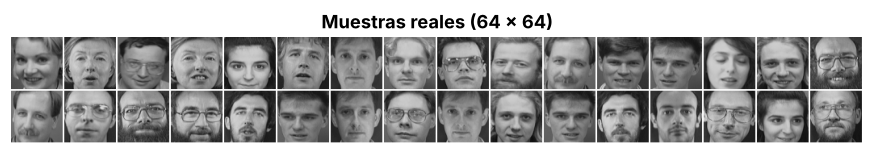

In [3]:
X = torch.tensor(cargar_rostros(64))
print("Rostros:", tuple(X.shape), "| rango:", round(X.min().item(), 2), "a", round(X.max().item(), 2))
fig, ax = plt.subplots(figsize=(10, 2.6)); mosaico(X[torch.randperm(400)[:32]], 2, ax, "Muestras reales (64 × 64)")
guardar(fig, "01_reales"); plt.show()

## 2. Arquitectura

In [4]:
print(inspect.getsource(Generador)); print(inspect.getsource(Discriminador))
G, D = Generador().to(dispositivo), Discriminador().to(dispositivo)
G.apply(iniciar_pesos); D.apply(iniciar_pesos)
print(f"Parámetros — Generador: {sum(p.numel() for p in G.parameters()):,} | Discriminador: {sum(p.numel() for p in D.parameters()):,}")
z = torch.randn(2, DIM_Z, device=dispositivo)
print("z", tuple(z.shape), "→ G(z)", tuple(G(z).shape), "→ D(G(z))", tuple(D(G(z)).shape))

class Generador(nn.Module):
    def __init__(self, dim_z=DIM_Z, ngf=48, canales=1):
        super().__init__()
        def bloque(c_in, c_out):
            return [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(True)]
        self.red = nn.Sequential(
            nn.ConvTranspose2d(dim_z, ngf * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf * 8), nn.ReLU(True),  # 4x4
            *bloque(ngf * 8, ngf * 4),   # 8x8
            *bloque(ngf * 4, ngf * 2),   # 16x16
            *bloque(ngf * 2, ngf),       # 32x32
            nn.ConvTranspose2d(ngf, canales, 4, 2, 1, bias=False), nn.Tanh())  # 64x64, valores en [-1, 1]

    def forward(self, z):
        return self.red(z.view(z.size(0), -1, 1, 1))

class Discriminador(nn.Module):
    def __init__(self, ndf=48, canales=1):
        super().__init__()
        def bloque(c_in, c_out):
            return [nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False), nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2, True)]
        self.

Parámetros — Generador: 2,164,896 | Discriminador: 1,556,544
z (2, 100) → G(z) (2, 1, 64, 64) → D(G(z)) (2,)


## 3. Entrenamiento adversarial

In [5]:
print(inspect.getsource(paso_entrenamiento))

def paso_entrenamiento(G, D, opt_G, opt_D, reales, dim_z=DIM_Z, etiqueta_real=0.9):
    """Un paso del entrenamiento adversarial. Devuelve pérdidas y salidas medias de D.

    1) Discriminador: maximizar log D(x) + log(1 − D(G(z)))  (BCE con reales = 0.9, falsas = 0)
       - 'label smoothing' unilateral (0.9) evita que D se vuelva demasiado confiado.
    2) Generador: maximizar log D(G(z))  (BCE de las falsas contra la etiqueta 1)
    """
    bce = nn.BCEWithLogitsLoss()
    B = reales.size(0)
    z = torch.randn(B, dim_z, device=reales.device)
    falsas = G(z)
    # --- 1. Discriminador ---
    opt_D.zero_grad()
    out_real = D(reales)
    out_falsa = D(falsas.detach())                 # detach: no propagar al generador
    loss_D = bce(out_real, torch.full_like(out_real, etiqueta_real)) + bce(out_falsa, torch.zeros_like(out_falsa))
    loss_D.backward()
    opt_D.step()
    # --- 2. Generador ---
    opt_G.zero_grad()
    out = D(falsas)
    loss_G = bce(out, torch.ones_like(out))

In [6]:
EPOCAS, LOTE = 250, 32
opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
z_fijo = torch.randn(32, DIM_Z, device=dispositivo)       # mismo ruido para ver la evolución
hist, instantaneas = [], {}
g = torch.Generator().manual_seed(0)
t0 = time.time()
for ep in range(1, EPOCAS + 1):
    G.train(); D.train()
    perm = torch.randperm(len(X), generator=g)
    for i in range(0, len(X) - LOTE + 1, LOTE):
        xb = X[perm[i:i + LOTE]]
        espejo = torch.rand(len(xb), 1, 1, 1, generator=g) < 0.5
        xb = torch.where(espejo, xb.flip(3), xb).to(dispositivo)
        hist.append({"época": ep, **paso_entrenamiento(G, D, opt_G, opt_D, xb)})
    if ep in (1, 5, 20, 50, 100, 175, 250):
        G.eval()
        with torch.no_grad(): instantaneas[ep] = G(z_fijo).cpu()
    if ep % 25 == 0:
        h = pd.DataFrame(hist); u = h[h["época"] == ep].mean()
        print(f"Época {ep:3d} | loss_D {u.loss_D:.3f} | loss_G {u.loss_G:.3f} | D(x) {u.D_x:.2f} | D(G(z)) {u.D_G_z:.2f} | {time.time() - t0:.0f} s")
hist = pd.DataFrame(hist)
torch.save(G.state_dict(), "modelos/dcgan_generador.pt")

Época  25 | loss_D 0.723 | loss_G 4.893 | D(x) 0.76 | D(G(z)) 0.14 | 84 s


Época  50 | loss_D 0.553 | loss_G 4.335 | D(x) 0.80 | D(G(z)) 0.10 | 166 s


Época  75 | loss_D 0.486 | loss_G 4.164 | D(x) 0.82 | D(G(z)) 0.07 | 251 s


Época 100 | loss_D 0.474 | loss_G 3.945 | D(x) 0.83 | D(G(z)) 0.07 | 334 s


Época 125 | loss_D 0.450 | loss_G 4.126 | D(x) 0.84 | D(G(z)) 0.06 | 413 s


Época 150 | loss_D 0.545 | loss_G 4.320 | D(x) 0.81 | D(G(z)) 0.09 | 493 s


Época 175 | loss_D 0.416 | loss_G 4.104 | D(x) 0.85 | D(G(z)) 0.04 | 577 s


Época 200 | loss_D 0.390 | loss_G 4.254 | D(x) 0.87 | D(G(z)) 0.03 | 661 s


Época 225 | loss_D 0.398 | loss_G 3.998 | D(x) 0.86 | D(G(z)) 0.04 | 741 s


Época 250 | loss_D 0.426 | loss_G 4.352 | D(x) 0.86 | D(G(z)) 0.04 | 825 s


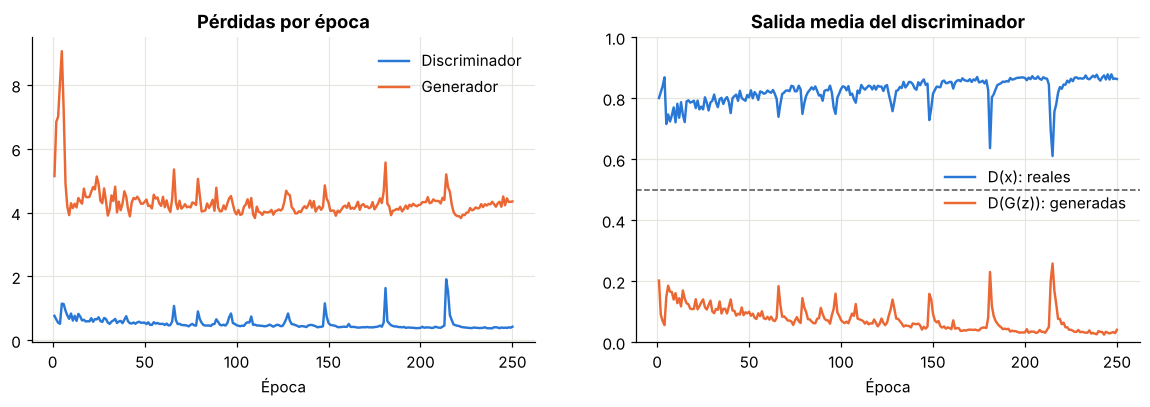

In [7]:
por_ep = hist.groupby("época").mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(por_ep.index, por_ep.loss_D, color=AZUL, label="Discriminador")
axes[0].plot(por_ep.index, por_ep.loss_G, color=NARANJA, label="Generador")
axes[0].set_title("Pérdidas por época"); axes[0].set_xlabel("Época"); axes[0].legend()
axes[1].plot(por_ep.index, por_ep.D_x, color=AZUL, label="D(x): reales")
axes[1].plot(por_ep.index, por_ep.D_G_z, color=NARANJA, label="D(G(z)): generadas")
axes[1].axhline(0.5, ls="--", color=GRIS, lw=1); axes[1].set_ylim(0, 1)
axes[1].set_title("Salida media del discriminador"); axes[1].set_xlabel("Época"); axes[1].legend()
guardar(fig, "01_curvas"); plt.show()

## 4. Generación de imágenes

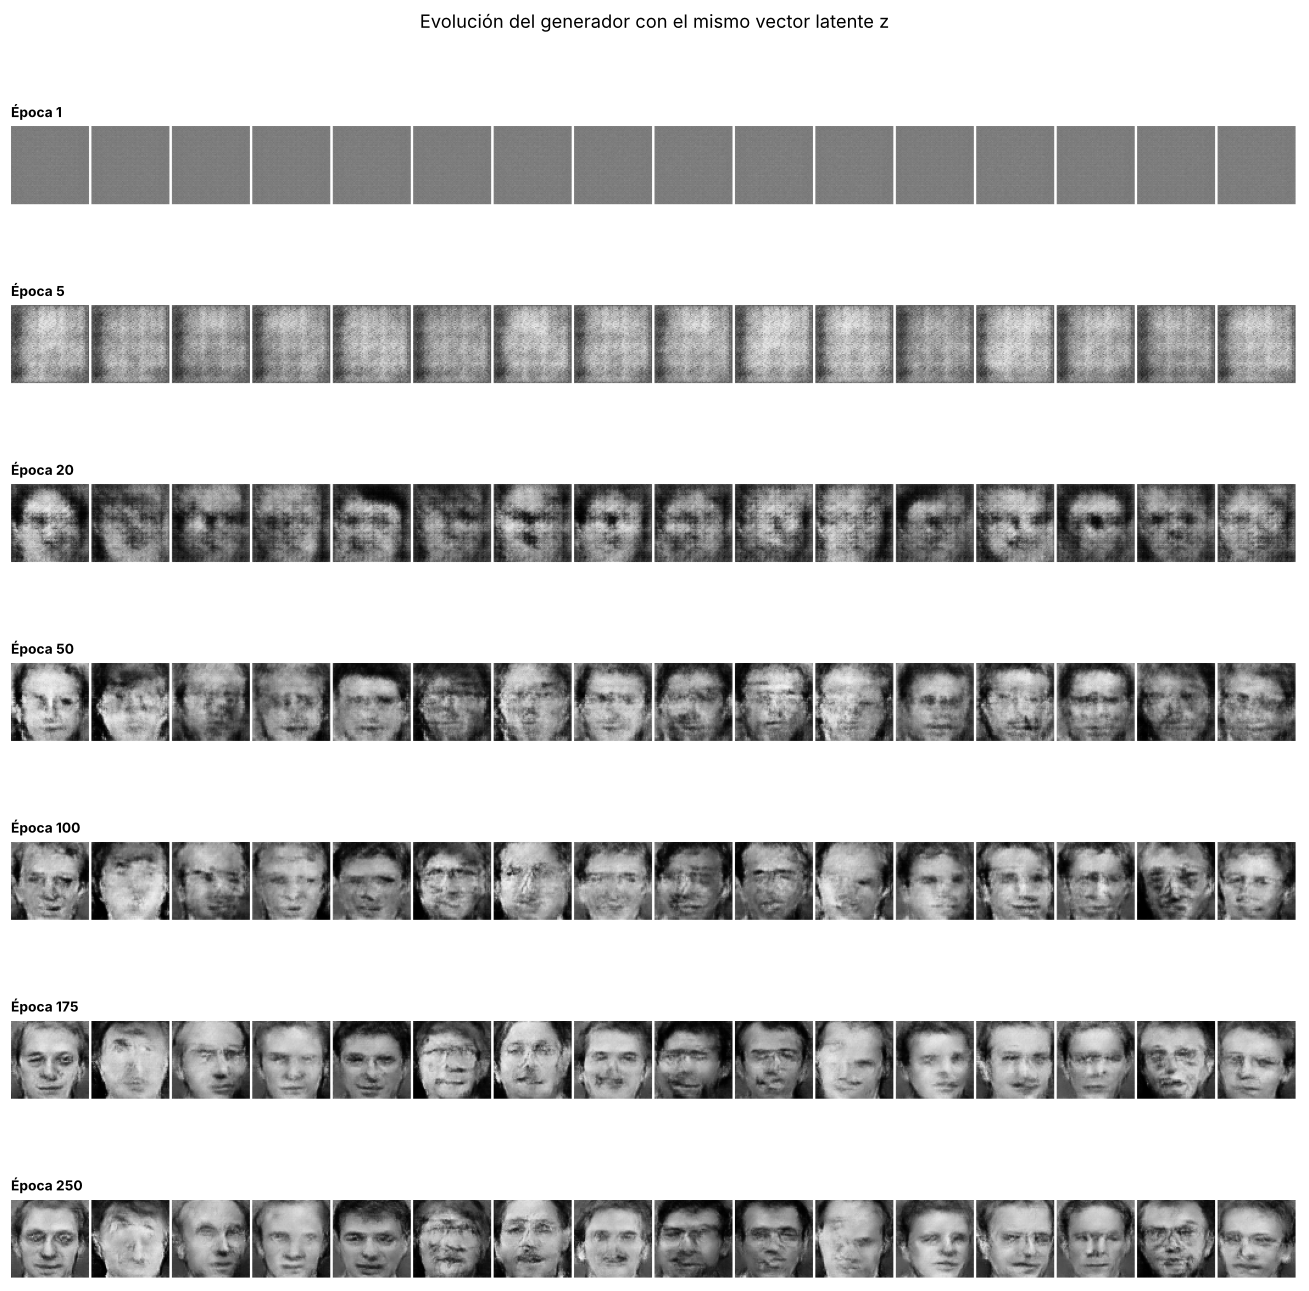

In [8]:
fig, axes = plt.subplots(len(instantaneas), 1, figsize=(12, 1.75 * len(instantaneas)))
for ax, (ep, imgs) in zip(axes, instantaneas.items()):
    mosaico(imgs[:16], 1, ax); ax.set_title(f"Época {ep}", loc="left", fontsize=9)
fig.suptitle("Evolución del generador con el mismo vector latente z", y=1.0)
fig.tight_layout(); guardar(fig, "01_evolucion"); plt.show()

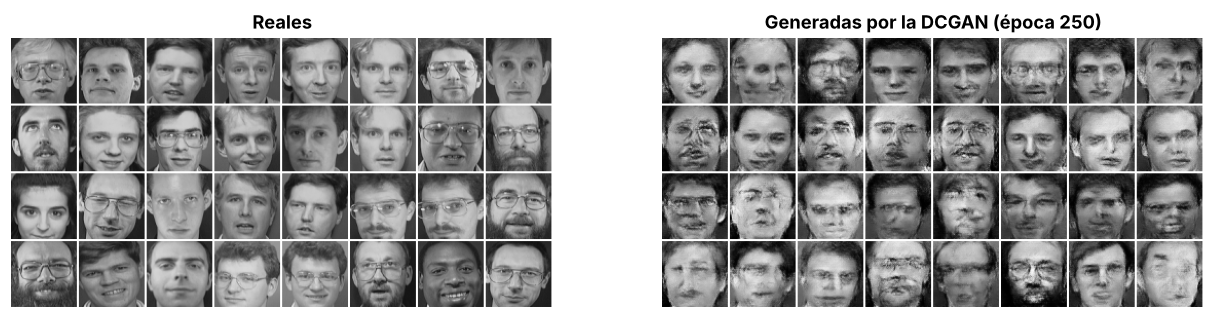

In [9]:
G.eval()
with torch.no_grad(): muestras = G(torch.randn(64, DIM_Z, device=dispositivo)).cpu()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mosaico(X[torch.randperm(400)[:32]], 4, axes[0], "Reales"); mosaico(muestras[:32], 4, axes[1], "Generadas por la DCGAN (época 250)")
guardar(fig, "01_reales_vs_generadas"); plt.show()

## 5. Espacio latente: interpolación esférica entre dos vectores z

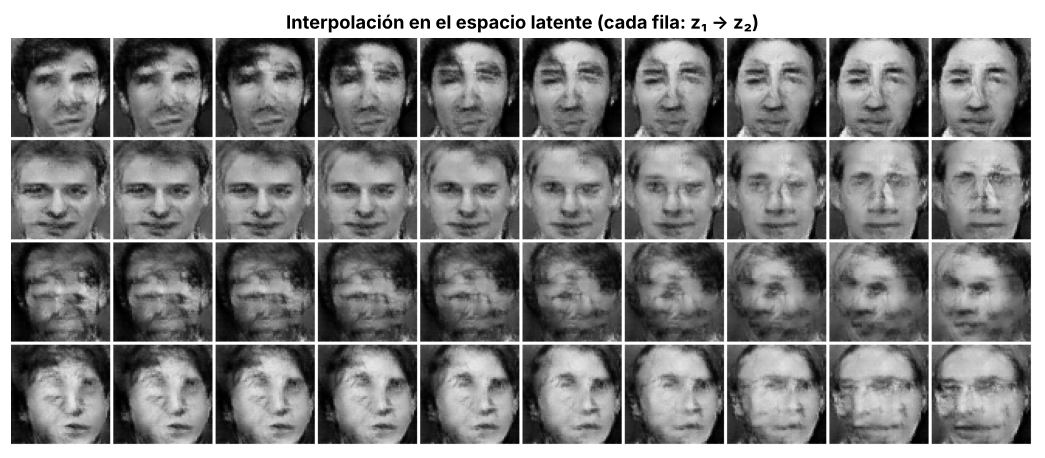

In [10]:
def slerp(a, b, t):
    """Interpolación esférica: recorre la hiperesfera donde se concentra N(0, I) en 100 dimensiones."""
    a_n, b_n = a / a.norm(), b / b.norm()
    omega = torch.acos((a_n * b_n).sum().clamp(-1, 1))
    return (torch.sin((1 - t) * omega) * a + torch.sin(t * omega) * b) / torch.sin(omega)
torch.manual_seed(3)
filas = []
for _ in range(4):
    a, b = torch.randn(DIM_Z), torch.randn(DIM_Z)
    filas.append(torch.stack([slerp(a, b, t) for t in torch.linspace(0, 1, 10)]))
with torch.no_grad(): interp = G(torch.cat(filas).to(dispositivo)).cpu()
fig, ax = plt.subplots(figsize=(12, 5)); mosaico(interp, 4, ax, "Interpolación en el espacio latente (cada fila: z₁ → z₂)")
guardar(fig, "01_interpolacion"); plt.show()

## 6. Análisis: ¿memoriza o genera? y diversidad

Distancia media generada → rostro real más cercano: 19.09  (real → otro real más cercano: 11.55)
Diversidad (distancia media entre pares): generadas 30.14 | reales 26.68  → razón 1.13


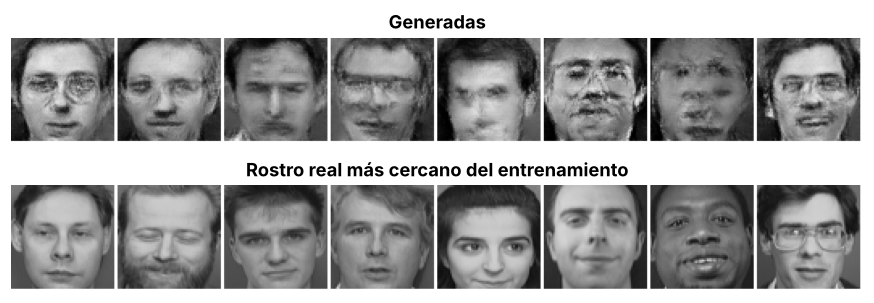

In [11]:
with torch.no_grad(): gen = G(torch.randn(256, DIM_Z, device=dispositivo)).cpu()
gv, rv = gen.view(256, -1), X.view(400, -1)
d = torch.cdist(gv, rv)                          # distancia de cada imagen generada a cada real
d_vecino = d.min(1).values
d_real_real = torch.cdist(rv, rv); d_real_real.fill_diagonal_(float("inf")); d_rr = d_real_real.min(1).values
div_gen = torch.pdist(gv).mean().item(); div_real = torch.pdist(rv).mean().item()
print(f"Distancia media generada → rostro real más cercano: {d_vecino.mean():.2f}  (real → otro real más cercano: {d_rr.mean():.2f})")
print(f"Diversidad (distancia media entre pares): generadas {div_gen:.2f} | reales {div_real:.2f}  → razón {div_gen / div_real:.2f}")
idx = torch.randperm(256)[:8]
fig, axes = plt.subplots(2, 1, figsize=(10, 3.2))
mosaico(gen[idx], 1, axes[0], "Generadas"); mosaico(X[d[idx].argmin(1)], 1, axes[1], "Rostro real más cercano del entrenamiento")
guardar(fig, "01_vecino_mas_cercano"); plt.show()
json.dump({"epocas": EPOCAS, "lote": LOTE, "segundos": time.time() - t0, "param_G": sum(p.numel() for p in G.parameters()),
           "param_D": sum(p.numel() for p in D.parameters()), "final": hist[hist["época"] > EPOCAS - 10].mean().to_dict(),
           "d_vecino_gen": d_vecino.mean().item(), "d_vecino_real": d_rr.mean().item(),
           "div_gen": div_gen, "div_real": div_real}, open("resultados/nb01.json", "w"), indent=2)

**Análisis.** Al inicio G produce ruido y D distingue fácilmente (D(x) ≈ 1, D(G(z)) ≈ 0); con las épocas aparecen la silueta,
luego ojos, nariz, boca y cabello. Las pérdidas no convergen a un mínimo como en un clasificador: oscilan porque cada red cambia
el problema de la otra (juego de suma cero). El espacio latente es continuo: interpolar entre dos z produce transiciones suaves de
pose, iluminación y rasgos. Con solo 400 imágenes, sin GPU y pocas horas, los rostros son reconocibles pero borrosos y de detalle
limitado; la comparación con el vecino más cercano verifica si el generador copia rostros del entrenamiento o los combina.